## Task 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("Module 7 - Exercises data.xlsx", sheet_name="Exercise 1")

df.head()

,Time (s),Wind speed (m/s)
0,0.000,16.27
1,0.025,16.20
2,0.050,16.13
3,0.075,16.06
4,0.100,15.99


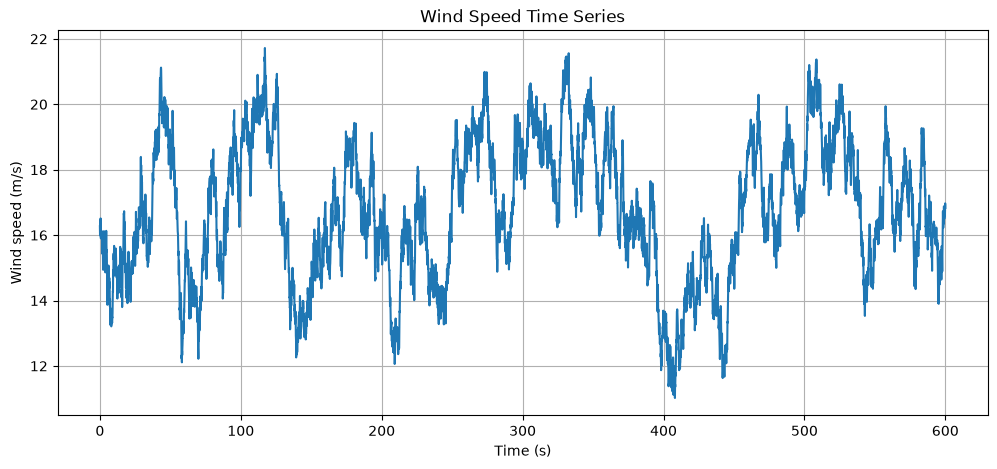

In [2]:
plt.figure(figsize=(12, 5))
plt.plot(df["Time (s)"], df["Wind speed (m/s)"])

plt.xlabel("Time (s)")
plt.ylabel("Wind speed (m/s)")
plt.title("Wind Speed Time Series")
plt.grid(True)

plt.show()

In [3]:
from scipy.fft import fft, fftfreq

# Extract data
time = df["Time (s)"].to_numpy()
wind = df["Wind speed (m/s)"].to_numpy()

# Sampling information
dt = time[1] - time[0]
N = len(wind)

# Fast Fourier Transform
spectrum = fft(wind - np.mean(wind))
freqs = fftfreq(N, d=dt)

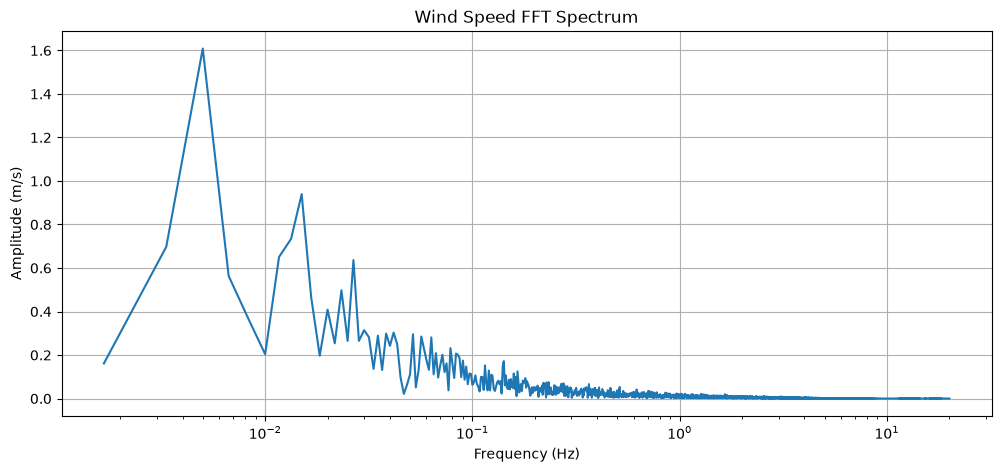

In [4]:
# Select positive frequencies (exclude 0 Hz)
mask = freqs > 0

# Calculate FFT magnitude
magnitude = np.abs(spectrum) * 2 / N

# Plot the frequency spectrum
plt.figure(figsize=(12, 5))
plt.plot(freqs[mask], magnitude[mask])

plt.xscale("log")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (m/s)")
plt.title("Wind Speed FFT Spectrum")
plt.grid(True)

plt.show()

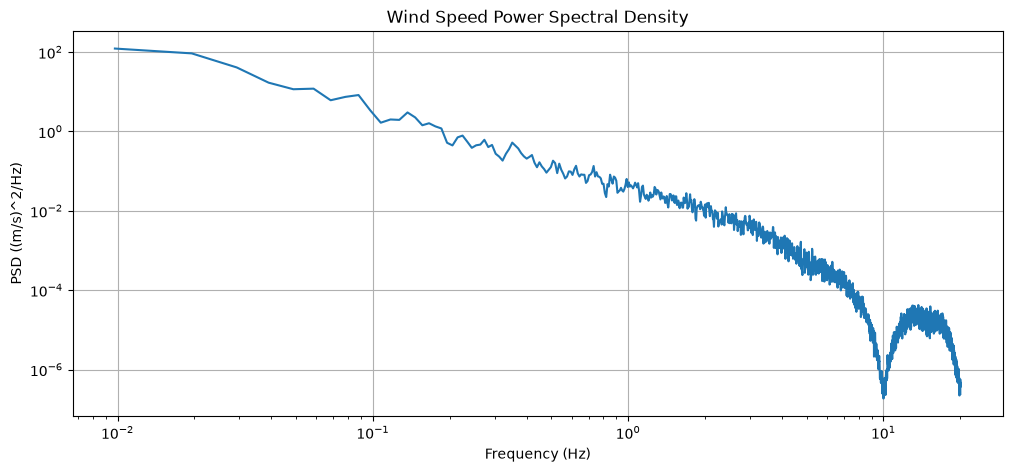

In [5]:
from scipy.signal import welch

# Calculate Power Spectral Density
fs = 1 / dt
psd_freqs, psd = welch(wind, fs=fs, nperseg=4096)

# Plot PSD
plt.figure(figsize=(12, 5))
plt.plot(psd_freqs[1:], psd[1:])

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD ((m/s)^2/Hz)")
plt.title("Wind Speed Power Spectral Density")
plt.grid(True)

plt.show()

## Answer - Part 2
**What frequency range dominates the signal and what does it signify about the wind?**

The wind speed signal is dominated by low frequencies, primarily below 0.1 Hz. The FFT shows particularly strong components around 0.005–0.02 Hz.

This indicates that the largest wind speed fluctuations occur over relatively long periods (tens to hundreds of seconds), while the higher-frequency variations are comparatively small.

In [6]:
from scipy.signal import butter, filtfilt

# Filter parameters
cutoff = 0.1   # Hz
order = 4

# Design Butterworth low-pass filter
b, a = butter(order, cutoff, btype="low", fs=fs)

# Apply filter
wind_filtered = filtfilt(b, a, wind)

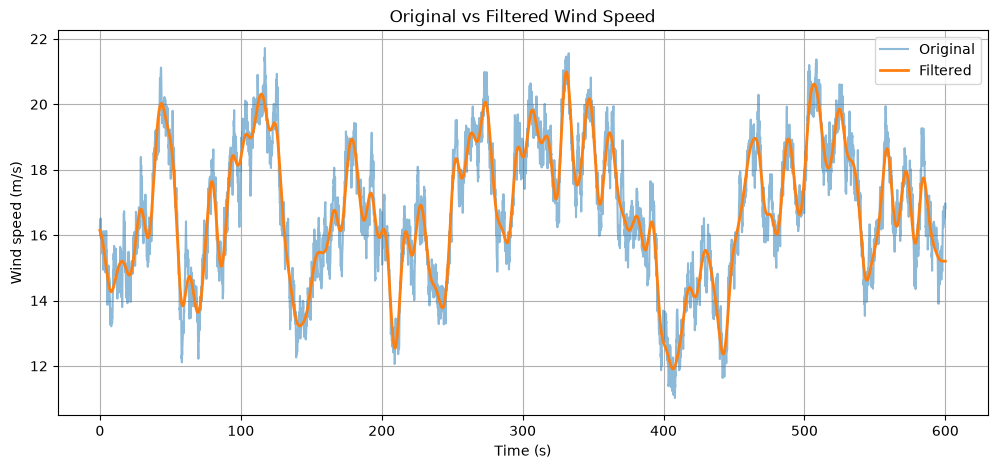

In [7]:
plt.figure(figsize=(12, 5))

plt.plot(time, wind, label="Original", alpha=0.5)
plt.plot(time, wind_filtered, label="Filtered", linewidth=2)

plt.xlabel("Time (s)")
plt.ylabel("Wind speed (m/s)")
plt.title("Original vs Filtered Wind Speed")
plt.legend()
plt.grid(True)

plt.show()

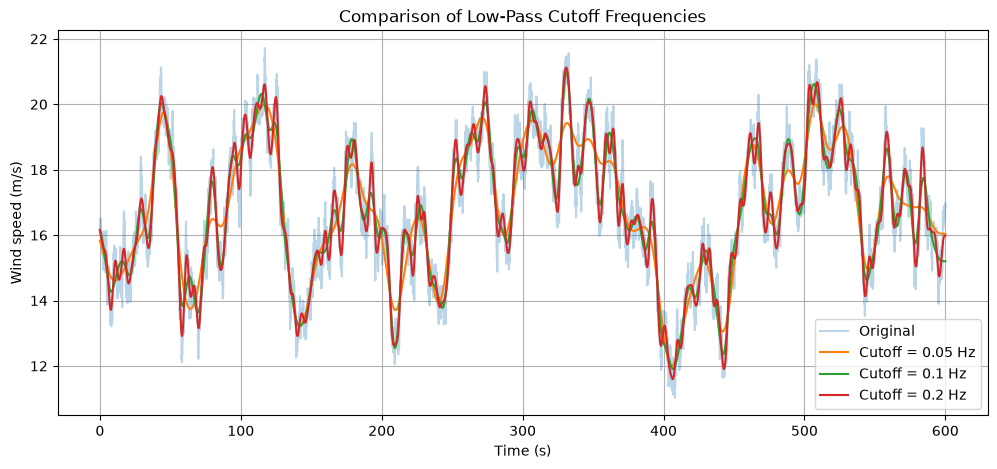

In [8]:
cutoffs = [0.05, 0.1, 0.2]

plt.figure(figsize=(12, 5))

plt.plot(time, wind, label="Original", alpha=0.3)

for cutoff in cutoffs:
    b, a = butter(4, cutoff, btype="low", fs=fs)
    filtered = filtfilt(b, a, wind)
    plt.plot(time, filtered, label=f"Cutoff = {cutoff} Hz")

plt.xlabel("Time (s)")
plt.ylabel("Wind speed (m/s)")
plt.title("Comparison of Low-Pass Cutoff Frequencies")
plt.legend()
plt.grid(True)

plt.show()

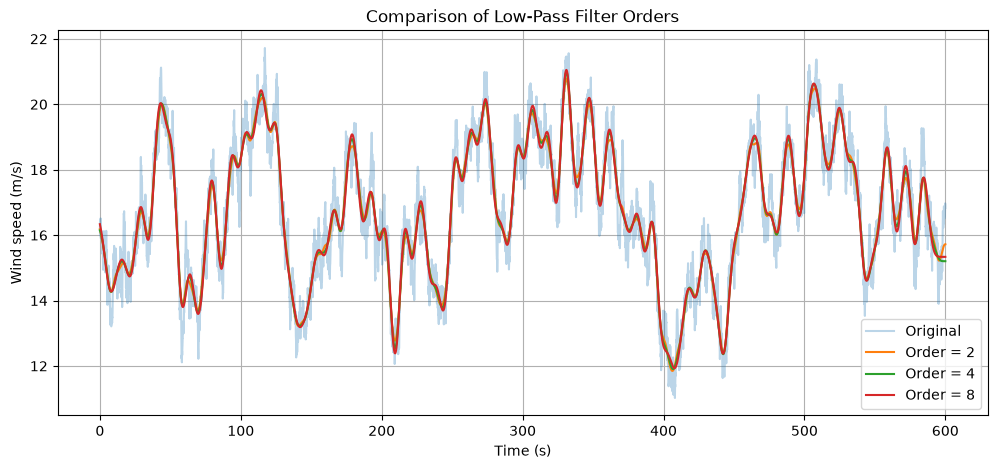

In [9]:
from scipy.signal import butter, sosfiltfilt

cutoff = 0.1
orders = [2, 4, 8]

plt.figure(figsize=(12, 5))
plt.plot(time, wind, label="Original", alpha=0.3)

for order in orders:
    sos = butter(order, cutoff, btype="low", fs=fs, output="sos")
    filtered = sosfiltfilt(sos, wind)
    plt.plot(time, filtered, label=f"Order = {order}")

plt.xlabel("Time (s)")
plt.ylabel("Wind speed (m/s)")
plt.title("Comparison of Low-Pass Filter Orders")
plt.legend()
plt.grid(True)

plt.show()

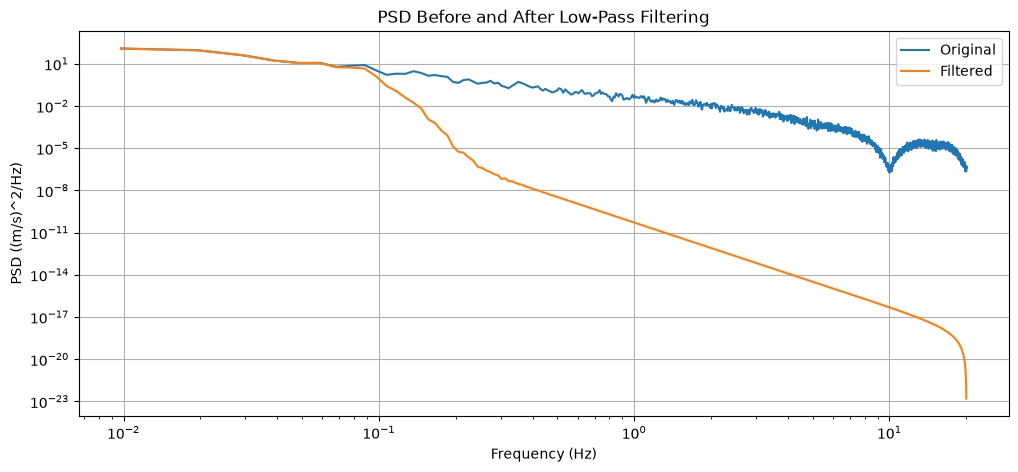

In [10]:
from scipy.signal import welch

# Choose filter parameters
cutoff = 0.1
order = 4

# Apply low-pass filter
sos = butter(order, cutoff, btype="low", fs=fs, output="sos")
wind_filtered = sosfiltfilt(sos, wind)

# Calculate PSD for both signals
freq_original, psd_original = welch(wind, fs=fs, nperseg=4096)
freq_filtered, psd_filtered = welch(wind_filtered, fs=fs, nperseg=4096)

# Plot comparison
plt.figure(figsize=(12, 5))

plt.loglog(freq_original[1:], psd_original[1:], label="Original")
plt.loglog(freq_filtered[1:], psd_filtered[1:], label="Filtered")

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD ((m/s)^2/Hz)")
plt.title("PSD Before and After Low-Pass Filtering")
plt.legend()
plt.grid(True)

plt.show()

## Answer - Part 3
**Which cutoff frequency is most suitable for smoothing out the signal whilst retaining the important information?**

A Butterworth low-pass filter with a cutoff frequency of **0.1 Hz and an order of 4** provides a suitable balance between smoothing the wind speed signal and retaining the important low-frequency variations.

Comparisons of cutoff frequencies at 0.05, 0.1 and 0.2 Hz show that 0.1 Hz preserves the main wind speed fluctuations while effectively reducing higher-frequency variations. The PSD comparison confirms that the lower frequencies are retained, while higher frequencies are strongly attenuated.

## Task 2

In [11]:
# Task 2 - Part 1
pitch_df = pd.read_excel(
    "Module 7 - Exercises data.xlsx",
    sheet_name="Exercise 2"
)

pitch_df.head()

,Wind speed (m/s),Blade pitch (degrees)
0,3,4.132
1,4,3.967
2,5,2.810
3,6,1.488
4,7,0.000


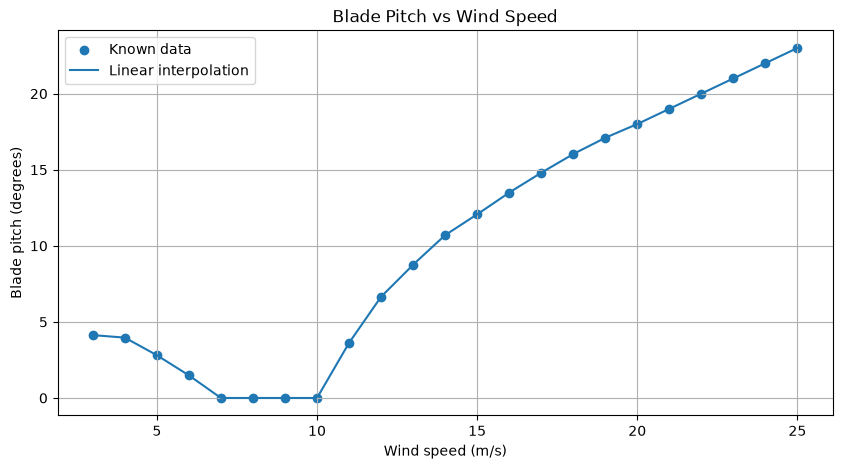

In [12]:
from scipy.interpolate import interp1d

# Extract data
wind_speed = pitch_df["Wind speed (m/s)"].to_numpy()
blade_pitch = pitch_df["Blade pitch (degrees)"].to_numpy()

# Create interpolation function
pitch_interp = interp1d(wind_speed, blade_pitch, kind="linear")

# Generate points for a smooth plot
wind_new = np.linspace(wind_speed.min(), wind_speed.max(), 200)
pitch_new = pitch_interp(wind_new)

plt.figure(figsize=(10, 5))

plt.scatter(wind_speed, blade_pitch, label="Known data")
plt.plot(wind_new, pitch_new, label="Linear interpolation")

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Blade pitch (degrees)")
plt.title("Blade Pitch vs Wind Speed")
plt.legend()
plt.grid(True)

plt.show()

In [13]:
# Calculate pitch from filtered wind speeds
pitch_time_series = pitch_interp(wind_filtered)

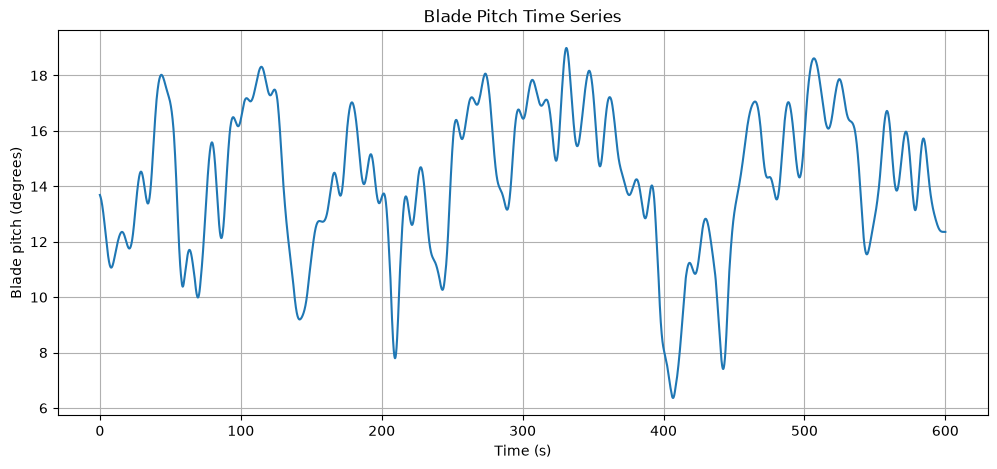

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(time, pitch_time_series)

plt.xlabel("Time (s)")
plt.ylabel("Blade pitch (degrees)")
plt.title("Blade Pitch Time Series")
plt.grid(True)

plt.show()

## Task 3

In [15]:
# Task 3 - Part 1
weibull_df = pd.read_excel(
    "Module 7 - Exercises data.xlsx",
    sheet_name="Exercise 3"
)

weibull_df.head()

,Date/Time,Wind Speed (m/s)
0,2013-01-01 00:00:00,8.79
1,2013-01-01 03:00:00,9.24
2,2013-01-01 06:00:00,5.82
3,2013-01-01 09:00:00,3.93
4,2013-01-01 12:00:00,3.88


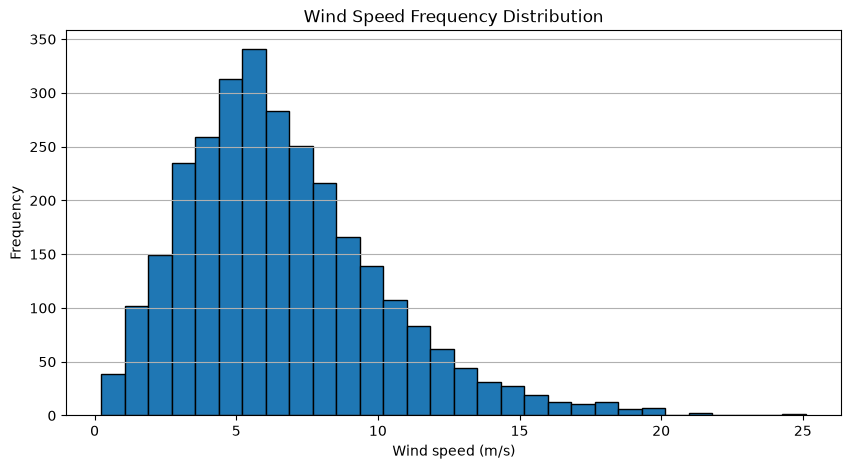

In [16]:
# Extract wind speed data
wind_weibull = weibull_df["Wind Speed (m/s)"].dropna().to_numpy()

# Plot histogram
plt.figure(figsize=(10, 5))
plt.hist(wind_weibull, bins=30, edgecolor="black")

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Frequency")
plt.title("Wind Speed Frequency Distribution")
plt.grid(axis="y")

plt.show()

In [17]:
from scipy.stats import weibull_min

# Fit Weibull distribution to measured wind speeds
k, loc, A = weibull_min.fit(wind_weibull, floc=0)

print(f"Shape parameter (k): {k:.3f}")
print(f"Scale parameter (A): {A:.3f} m/s")

Shape parameter (k): 2.026
Scale parameter (A): 7.535 m/s


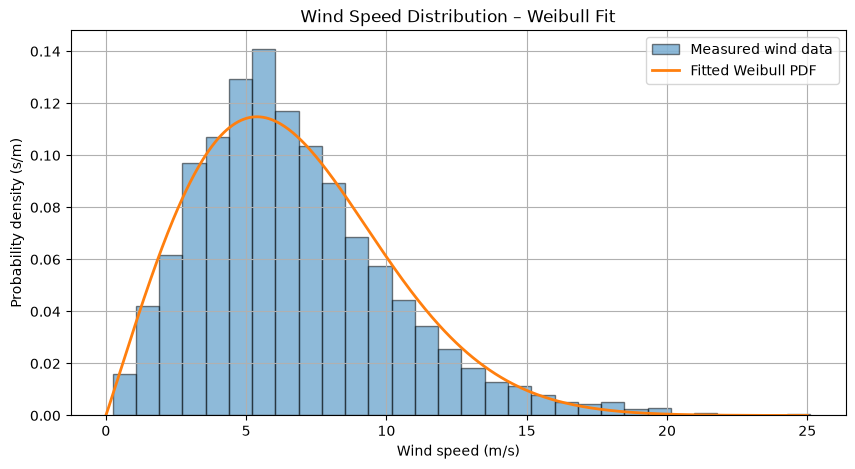

In [18]:
# Generate wind speeds for the Weibull curve
v = np.linspace(0, 25, 500)

# Calculate Weibull PDF
weibull_pdf = weibull_min.pdf(v, k, loc=0, scale=A)

# Plot histogram and fitted Weibull distribution
plt.figure(figsize=(10, 5))

plt.hist(wind_weibull, bins=30, density=True,
         alpha=0.5, edgecolor="black", label="Measured wind data")

plt.plot(v, weibull_pdf, linewidth=2,
         label="Fitted Weibull PDF")

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Probability density (s/m)")
plt.title("Wind Speed Distribution – Weibull Fit")
plt.legend()
plt.grid(True)

plt.show()

## Task 4

In [19]:
# Task 4 - Turbine power curve

rho = 1.225
Cp = 0.45
V_in = 3
V_out = 25

def turbine_power(D, Vr):
    # Calculate rated power
    P_rated = 0.5 * rho * np.pi * (D / 2)**2 * Cp * Vr**3

    return P_rated

print(f"Rated power: {turbine_power(120, 10) / 1e6:.2f} MW")

Rated power: 3.12 MW


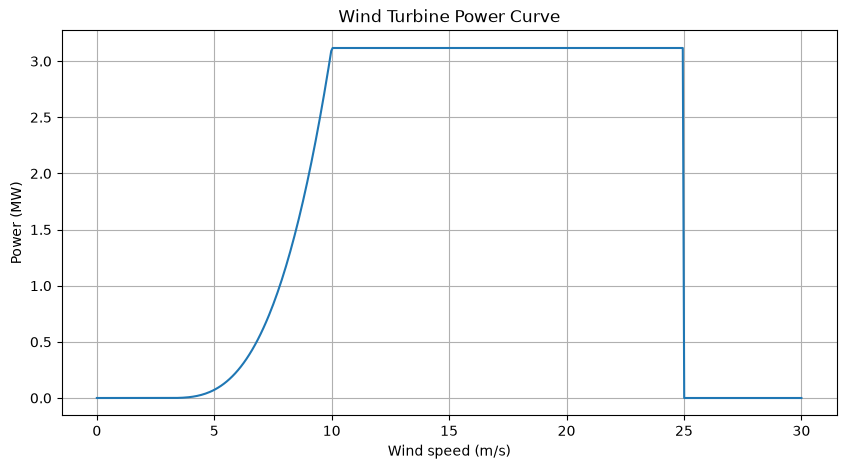

In [20]:
def turbine_power(D, Vr, V):
    # Calculate rated power
    P_rated = 0.5 * rho * np.pi * (D / 2)**2 * Cp * Vr**3

    # Calculate power at each wind speed
    P = np.zeros_like(V)

    mask_2 = (V >= V_in) & (V < Vr)
    mask_3 = (V >= Vr) & (V < V_out)

    P[mask_2] = P_rated * ((V[mask_2] - V_in) / (Vr - V_in))**3
    P[mask_3] = P_rated

    return P


V = np.linspace(0, 30, 500)
P = turbine_power(120, 10, V)

plt.figure(figsize=(10, 5))
plt.plot(V, P / 1e6)

plt.xlabel("Wind speed (m/s)")
plt.ylabel("Power (MW)")
plt.title("Wind Turbine Power Curve")
plt.grid(True)

plt.show()

In [21]:
def calculate_AEP(D, Vr):
    V = np.linspace(0, 30, 1000)

    # Turbine power curve
    P = turbine_power(D, Vr, V)

    # Wind speed probability density
    pdf = weibull_min.pdf(V, k, loc=0, scale=A)

    # Annual energy production
    AEP = 8760 * np.trapezoid(P * pdf, V)

    return AEP



AEP = calculate_AEP(120, 10)

print(f"Annual Energy Production: {AEP / 1e9:.2f} GWh")

Annual Energy Production: 8.55 GWh


In [22]:
from scipy.optimize import minimize

# Objective function
def objective(x):
    D, Vr = x
    return -calculate_AEP(D, Vr) / 1e9


from scipy.optimize import NonlinearConstraint, LinearConstraint

# Rated power must not exceed 10 MW
def rated_power(x):
    D, Vr = x
    return 0.5 * rho * np.pi * (D / 2)**2 * Cp * Vr**3

power_constraint = NonlinearConstraint(
    rated_power, 0, 10e6
)

# Rotor radius must not exceed 80 m
radius_constraint = LinearConstraint(
    [[0.5, 0]], -np.inf, 80
)

In [23]:
# Bounds for [D, Vr]
bounds = [(50, 160), (4, 20)]

# Initial values
x0 = [120, 10]

# Run optimization
result = minimize(
    objective,
    x0,
    method="trust-constr",
    bounds=bounds,
    constraints=[power_constraint, radius_constraint],
    options={"maxiter": 5000}
)

# Extract optimal design
D_opt, Vr_opt = result.x

# Calculate rated power and AEP
P_opt = rated_power(result.x)
AEP_opt = calculate_AEP(D_opt, Vr_opt)

print("Optimization successful:", result.success)
print(f"Optimal rotor diameter: {D_opt:.2f} m")
print(f"Optimal rated wind speed: {Vr_opt:.2f} m/s")
print(f"Rated power: {P_opt / 1e6:.2f} MW")
print(f"Annual Energy Production: {AEP_opt / 1e9:.2f} GWh")

c:\Users\fsd\AppData\Local\miniconda3\Lib\site-packages\scipy\optimize\_differentiable_functions.py:737: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(delta_x, delta_g)
c:\Users\fsd\AppData\Local\miniconda3\Lib\site-packages\scipy\optimize\_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


Optimization successful: True
Optimal rotor diameter: 160.00 m
Optimal rated wind speed: 12.17 m/s
Rated power: 10.00 MW
Annual Energy Production: 17.56 GWh
